In [1]:
'''
Go to pyjetty env
Use command  `jupyter notebook --no-browser --port=8888 --ServerApp.disable_check_xsrf=True`
copy localhost URL
click "select kernel"
choose existing jupyter server --> paste the URL --> enter (localhost) --> python3
'''

'\nGo to pyjetty env\nUse command  `jupyter notebook --no-browser --port=8888 --ServerApp.disable_check_xsrf=True`\ncopy localhost URL\nclick "select kernel"\nchoose existing jupyter server --> paste the URL --> enter (localhost) --> python3\n'

In [3]:
import os
import numpy as np
import pandas as pd
import uproot as ur

import sys
sys.path.append('../')
utils_path = '/global/cfs/cdirs/alice/blianggi/mypyjetty/pyjetty/pyjetty/alice_analysis/analysis/user/jse/3Dunfolding/'
if utils_path not in sys.path:
    sys.path.insert(0, utils_path)
from jupyter_utils import *

from matplotlib import pyplot as plt
from IPython.display import Image
pd.set_option('display.max_columns', None) # to see all columns of df.head()
pd.set_option('display.max_rows', None)

from matplotlib.patches import PathPatch
from matplotlib.path import Path
import matplotlib.ticker as ticker

# Lauren's colors
L_colors = ['red', 'darkorange', 'limegreen', 'green', 'deepskyblue', 'blue', 'black', 'gold', 'hotpink']
L_linestyles = ['solid', 'dashed']
L_markers = ['s', '^', 'v', 'd', 'P', "X", "*", "o", '8']

In [3]:
'''
def get_lin_bincenters(bin_edges):
    """
    Calculates the midpoints (centers) of linear bins from an array of bin edges.
    """
    return (bin_edges[:-1] + bin_edges[1:]) / 2.0

def get_log_bincenters(bin_edges):
    """
    Calculates the geometric midpoints (log centers) of bins from an array of bin edges.
    """
    # Standard formula using the geometric mean (square root of the product of edges)
    return np.sqrt(bin_edges[:-1] * bin_edges[1:])

def get_binwidths(bin_edges):
    """
    Calculates the width of each bin from an array of bin edges.
    """
    return np.diff(bin_edges)

def safe_divide(numerator, denominator, filler=0.0):
    """
    Safely divides two arrays element-wise. Replaces division-by-zero 
    and NaN results with the specified filler value.
    """
    # Convert inputs to numpy arrays just in case they are passed as lists
    num = np.asarray(numerator, dtype=float)
    den = np.asarray(denominator, dtype=float)
    
    # Use np.divide's 'where' parameter to only divide where denominator is non-zero
    # Out determines what to place where the condition is False
    result = np.divide(num, den, out=np.full_like(num, filler), where=(den != 0.0))
    
    # Final safety sweep to catch any unexpected NaNs or Inf values
    result = np.nan_to_num(result, nan=filler, posinf=filler, neginf=filler)
    
    return result
'''

'\ndef get_lin_bincenters(bin_edges):\n    """\n    Calculates the midpoints (centers) of linear bins from an array of bin edges.\n    """\n    return (bin_edges[:-1] + bin_edges[1:]) / 2.0\n\ndef get_log_bincenters(bin_edges):\n    """\n    Calculates the geometric midpoints (log centers) of bins from an array of bin edges.\n    """\n    # Standard formula using the geometric mean (square root of the product of edges)\n    return np.sqrt(bin_edges[:-1] * bin_edges[1:])\n\ndef get_binwidths(bin_edges):\n    """\n    Calculates the width of each bin from an array of bin edges.\n    """\n    return np.diff(bin_edges)\n\ndef safe_divide(numerator, denominator, filler=0.0):\n    """\n    Safely divides two arrays element-wise. Replaces division-by-zero \n    and NaN results with the specified filler value.\n    """\n    # Convert inputs to numpy arrays just in case they are passed as lists\n    num = np.asarray(numerator, dtype=float)\n    den = np.asarray(denominator, dtype=float)\n\n    

In [4]:

# define binnings
n_bins = 9 #7 # WARNING RooUnfold seg faults if too many bins used
binning_reco = np.array([10, 20, 40, 60, 80, 100, 120, 150, 200, 500]).astype(float)
# binning_reco = np.array([20, 40, 60, 80, 100, 120, 150, 200]).astype(float)
bincenters_reco = get_lin_bincenters(binning_reco)
binwidths_reco = np.array(get_binwidths(binning_reco))

n_bins_true = 9 #7 # WARNING RooUnfold seg faults if too many bins used
binning = np.array([10, 20, 40, 60, 80, 100, 120, 150, 200, 500]).astype(float)
# binning = np.array([20, 40, 60, 80, 100, 120, 150, 200]).astype(float)
bincenters = get_lin_bincenters(binning)
binwidths = np.array(get_binwidths(binning))

labels = "jet $p_T$"

n_iter = 5 #9 #5

In [5]:
# file defs, hist imports

f_unfolded = ur.open("/global/cfs/cdirs/alice/blianggi/mypyjetty/storage/jse/rootfiles/unfolding/unfolded1D.root")
# f_preunfold_rm = ur.open("/global/cfs/cdirs/alice/alicepro/hiccup/rstorage/alice/AnalysisResults/blianggi/jse/rms/57911278/response_groomed_forunfolding_merged.root")
f_preunfold_rm = ur.open("/global/cfs/cdirs/alice/alicepro/hiccup/rstorage/alice/AnalysisResults/blianggi/jse/rms/58919321/response_groomed_forunfolding_merged.root")
f_preunfold_data = ur.open("/global/cfs/cdirs/alice/alicepro/hiccup/rstorage/alice/AnalysisResults/blianggi/jse/data/60017705/AnalysisResultsMerged_groomedbins.root")

# Data, reco [theta_unknown_S]
h1_raw = f_preunfold_data["groomed_sd0.1_jet_pt_raw1D"]

# MC, reco [theta0_S]
h1_reco = f_preunfold_rm["jet_match_rec_pur_num_groomed"]

# MC, true [theta0_G]
h1_gen = f_preunfold_rm["jet_match_gen_eff_num_groomed"]

h1_unfolded = []
for i in range(1,n_iter+1):
    h1_unfolded.append(f_unfolded["Baysian_Unfolded1Diter{}".format(i)])


In [6]:
proj = lambda a : a.values()
proj_err = lambda a : a.errors()
proj_err_unf = lambda a : np.sqrt(a.errors()**2 + a.values())

theta0_G = proj(h1_gen)
theta0_S = proj(h1_reco)
theta_unknown_S = proj(h1_raw)

theta_unfolded = [proj(a) for a in h1_unfolded]

theta0_G_err = proj_err(h1_gen)
theta0_S_err = proj_err(h1_reco)
theta_unknown_S_err = proj_err(h1_raw)

theta_unfolded_err = [proj_err_unf(a) for a in h1_unfolded]


In [7]:
# print total number of jets
print("######### UNFOLDED JETS #########")
print(theta_unfolded[-1])
print(theta_unfolded_err[-1])
for i in range(len(theta_unfolded)):
    print("\t i={}, {} +/- {}".format(i, np.sum(theta_unfolded[i]), np.sum(theta_unfolded_err[i])))
print("total det jets : {} \n".format(np.sum(theta_unfolded[-1]) ))

print("######### RAW JETS #########")
print(theta_unknown_S)
print("total det jets : {} \n".format(np.sum(theta_unknown_S) ))

# TODO propagate error from here to actaul eec calculation

# print number of jets in mc
print("##### NOW MC JETS #####")
print("matched gen:")
print(theta0_G)
print("matched reco:")
print(theta0_S)

######### UNFOLDED JETS #########
[3.54802193e+08 2.60231163e+07 1.45773558e+06 2.38979182e+05
 6.08993183e+04 2.05908120e+04 9.97131242e+03 3.72692301e+03
 1.00942203e+03]
[8.40347572e+05 9.14919315e+04 6.21155231e+03 1.37643791e+03
 4.86804260e+02 2.38952539e+02 1.59677389e+02 9.72663750e+01
 5.46312605e+01]
	 i=0, 382251106.7856872 +/- 872157.3472642114
	 i=1, 382431646.2558161 +/- 905375.355479141
	 i=2, 382531282.20681477 +/- 924225.9233712248
	 i=3, 382586794.7934848 +/- 934598.2536929473
	 i=4, 382618222.2170971 +/- 940464.82578229
total det jets : 382618222.2170971 

######### RAW JETS #########
[1.94454918e+08 1.54774580e+07 8.17665000e+05 1.19585000e+05
 2.77460000e+04 8.40000000e+03 2.99400000e+03 6.80000000e+02
 6.50000000e+01]
total det jets : 210909511.0 

##### NOW MC JETS #####
matched gen:
[7.03300822e+05 7.21047498e+04 3.87044358e+03 5.76125694e+02
 1.37783569e+02 4.30909328e+01 1.99419287e+01 7.20093827e+00
 1.85381064e+00]
matched reco:
[5.57195604e+05 4.16105626e+0

In [8]:
# ############################## Wenqing's distros ############################

# f_compare = ur.open("./hists_jet_pt_agg.root")

# h1_compare = f_compare["hJetPt_R04_shape_pythiaMC"]
# bins_compare = h1_compare.axis('x').edges()
# h1_compare = h1_compare.values()

# print(bins_compare)

# print(binning)

# def rebinnew_binning(new_binning, values):
#     # only works for this one case

#     new_values = []
#     for i in range(len(new_binning)-1):
#         new_values.append(np.sum([values[j] for j in range(int(new_binning[i]), int(new_binning[i+1]+1))]))
#     return new_values

# print(len(rebinnew_binning(binning, h1_compare)))
# print(rebinnew_binning(binning, h1_compare))

# h1_compare = np.array(rebinnew_binning(binning, h1_compare)) / binwidths


[1.94454918e+08 1.54774580e+07 8.17665000e+05 1.19585000e+05
 2.77460000e+04 8.40000000e+03 2.99400000e+03 6.80000000e+02
 6.50000000e+01]
[3.54802193e+08 2.60231163e+07 1.45773558e+06 2.38979182e+05
 6.08993183e+04 2.05908120e+04 9.97131242e+03 3.72692301e+03
 1.00942203e+03]


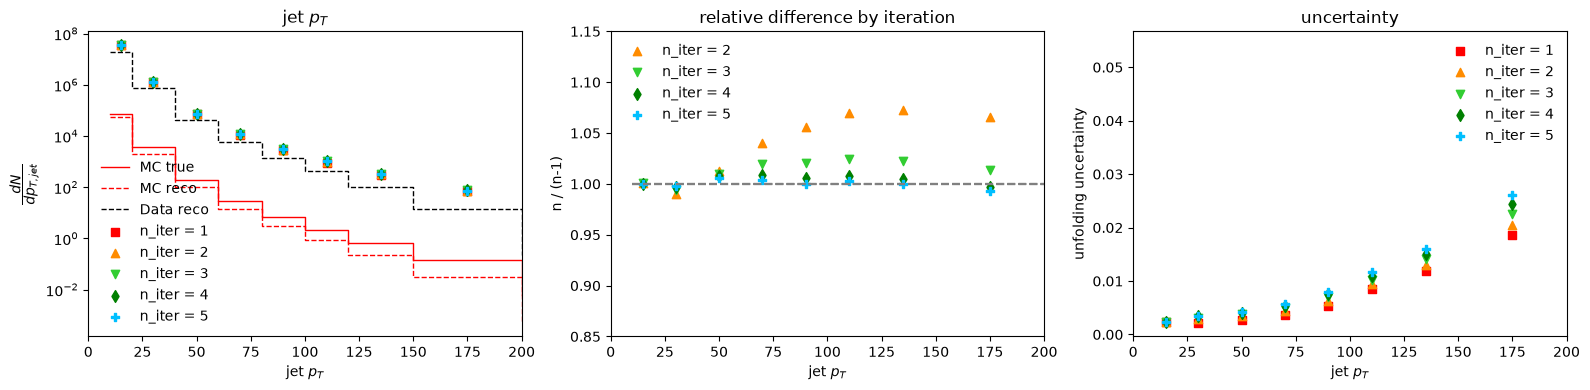

In [8]:
############################## UNFOLDED DISTRIBUTIONS ############################
# EEC distros

it = 5 #9 #5

fig, axes = plt.subplots(1, 3, figsize=(16,4))

pt_lims = [0, 200] #150]

# COL 1: raw jet pt distribution WITH relative error over data, true underneath
ax = axes[0]

# comparison with Wenqing's PythiaMC distribution
# norm = (theta_unfolded[-1][3] / h1_compare[2])
# ax.step(binning[:-1], h1_compare * norm, where="post",color='black',label="PythiaMC, compare",lw=1)
# ax.step(binning[:-2], theta0_G / binwidths[:-1], where="post",color='red',label="MC true",lw=1)
ax.step(binning[:-1], theta0_G / binwidths, where="post",color='red',label="MC true",lw=1)
ax.step(binning_reco[:-1], theta0_S / binwidths_reco, where="post",color='red',linestyle='--',label="MC reco",lw=1)
ax.step(binning_reco[:-1], theta_unknown_S / binwidths_reco, where="post",color='black',linestyle='--',label="Data reco",lw=1)

print(theta_unknown_S)
print(theta_unfolded[-1])

for iteration in range(it):

    ax.scatter(bincenters, theta_unfolded[iteration] / binwidths,color=L_colors[iteration],marker=L_markers[iteration],label="n_iter = {}".format(iteration+1),lw=1)
    ax.set_ylabel("$\\frac{dN}{dp_{T,jet}}$", fontsize=14)
    
    ax.set_title(labels)
    ax.set_xlabel(labels)
    ax.set_yscale('log')

    ax.legend(frameon=False)

    ax.set_xlim(pt_lims)

# ax.yaxis.set_major_locator(ticker.LogLocator(base=10.0, numticks=12))
# ax.yaxis.set_minor_locator(ticker.LogLocator(base=10.0, subs=(5.0,), numticks=12))
# ax.grid(True, which='major', linestyle='-', alpha=0.5)
# ax.grid(True, which='minor', color='gray', linestyle='--', alpha=0.4)

# COL 2: convergence plot (n / n - 1)
ax = axes[1]

for iteration in range(1,it):

    yvals = safe_divide(theta_unfolded[iteration], theta_unfolded[iteration-1], filler=1)
    ax.scatter(bincenters, yvals, color=L_colors[iteration],marker=L_markers[iteration],label="n_iter = {}".format(iteration+1),lw=1)

    ax.hlines(y=1, xmin=binning[0], xmax=binning[len(binning)-1], color='grey', linestyle='--')

    ax.set_title('relative difference by iteration')
    ax.set_xlabel(labels)
    # ax.set_ylabel("$\left. \\frac{dN_n}{dR_L} \middle/ \\frac{dN_{n-1}}{dR_L} \\right.$", fontsize=14)
    ax.set_ylabel("n / (n-1)")
    ax.legend(frameon=False)

    ax.set_ylim([0.85, 1.15])
    ax.set_xlim(pt_lims)


# COL 3: statistical error %
ax = axes[2]

for iteration in range(it):
    
    yvals = safe_divide(theta_unfolded_err[iteration], theta_unfolded[iteration])
    ax.scatter(bincenters, yvals, color=L_colors[iteration],marker=L_markers[iteration],label="n_iter = {}".format(iteration+1),lw=1)

    ax.set_title('uncertainty')
    ax.set_xlabel(labels)
    ax.set_ylabel("unfolding uncertainty")
    ax.legend(frameon=False)

    ax.set_xlim(pt_lims)


fig.tight_layout()
plt.show()


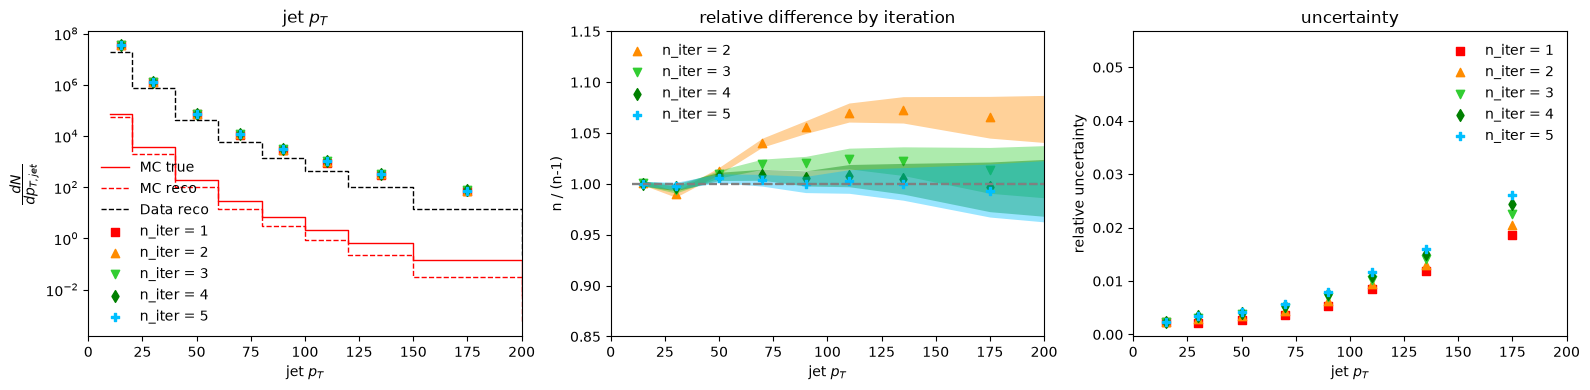

In [9]:
############################## UNFOLDED DISTRIBUTIONS ############################
# EEC distros

it = 5 #9 #5

fig, axes = plt.subplots(1, 3, figsize=(16,4))

pt_lims = [0, 200]

# COL 1: raw jet pt distribution WITH relative error over data, true underneath
ax = axes[0]

ax.step(binning[:-1], theta0_G / binwidths, where="post",color='red',label="MC true",lw=1)
ax.step(binning_reco[:-1], theta0_S / binwidths_reco, where="post",color='red',linestyle='--',label="MC reco",lw=1)
ax.step(binning_reco[:-1], theta_unknown_S / binwidths_reco, where="post",color='black',linestyle='--',label="Data reco",lw=1)

for iteration in range(it):

    ax.scatter(bincenters, theta_unfolded[iteration] / binwidths,color=L_colors[iteration],marker=L_markers[iteration],label="n_iter = {}".format(iteration+1),lw=1)

    ax.set_ylabel("$\\frac{dN}{dp_{T,jet}}$", fontsize=14)
    ax.set_title(labels)
    ax.set_xlabel(labels)
    ax.set_yscale('log')

    ax.legend(frameon=False)

    ax.set_xlim(pt_lims)

# ax.yaxis.set_major_locator(ticker.LogLocator(base=10.0, numticks=12))
# ax.grid(True, which='major', linestyle='--', alpha=0.5)

# COL 2: convergence plot (n / n - 1)
ax = axes[1]

for iteration in range(1,it):

    yvals = safe_divide(theta_unfolded[iteration], theta_unfolded[iteration-1], filler=1)
    ax.scatter(bincenters, yvals, color=L_colors[iteration],marker=L_markers[iteration],label="n_iter = {}".format(iteration+1),lw=1)

    ax.hlines(y=1, xmin=binning[0], xmax=binning[len(binning)-1], color='grey', linestyle='--')

    ax.set_title('relative difference by iteration')
    ax.set_xlabel(labels)
    # ax.set_ylabel("$\left. \\frac{dN_n}{dR_L} \middle/ \\frac{dN_{n-1}}{dR_L} \\right.$", fontsize=14)
    ax.set_ylabel("n / (n-1)")
    ax.legend(frameon=False)

    ax.set_ylim([0.85, 1.15])
    ax.set_xlim(pt_lims)

    yerrs = safe_divide(theta_unfolded_err[iteration], theta_unfolded[iteration])
    ax.fill_between(bincenters, (yvals-yerrs), (yvals+yerrs), alpha=0.4, edgecolor=L_colors[iteration], facecolor=L_colors[iteration], linewidth=0)


# COL 3: statistical error %
ax = axes[2]

for iteration in range(it):
    
    yvals = safe_divide(theta_unfolded_err[iteration], theta_unfolded[iteration])
    ax.scatter(bincenters, yvals, color=L_colors[iteration],marker=L_markers[iteration],label="n_iter = {}".format(iteration+1),lw=1)

    ax.set_title('uncertainty')
    ax.set_xlabel(labels)
    ax.set_ylabel("relative uncertainty")
    ax.legend(frameon=False)

    ax.set_xlim(pt_lims)


fig.tight_layout()
plt.show()
